## AI-EXAFS Experimental Comparison 

### 1) PtCl6 Molecular Complex

In [1]:
# Importing standard libraries
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt

In [2]:
# Set figure defaults
width = 7  # 1/3 of a page
fontsize = 16
rc = {'figure.figsize': (width, width),
      'font.size': fontsize,
      'axes.labelsize': fontsize,
      'axes.titlesize': fontsize,
      'xtick.labelsize': fontsize,
      'ytick.labelsize': fontsize,
      'legend.fontsize': 14,
      "axes.linewidth":  1.5,}
sns.set(rc=rc)
sns.set_style('ticks')

In [3]:
# Utils
def get_array(a, b, target_dim=800):
    """Build a (target_dim, 2) array from two 1D arrays, interpolated to target_dim points."""
    from scipy import interpolate as interp

    def _interpolate(arr, target_dim):
        y_interp = interp.interp1d(np.arange(arr.size), arr)
        return y_interp(np.linspace(0, arr.size - 1, target_dim))

    arr = np.zeros((target_dim, 2))
    arr[:, 0] = _interpolate(a, target_dim)
    arr[:, 1] = _interpolate(b, target_dim)
    return arr

def r_factor(y_true, predictions):
    """Function that computes the R-factor metric used in EXAFS comparison"""
    y_true, predictions = np.array(y_true), np.array(predictions)
    a = np.sum(np.square(y_true - predictions))
    b = np.sum(np.square(y_true))
    return np.divide(a, b)

def slice_array(arr, xlim, target_dim=None):
    from scipy import interpolate as interp

    mask = (arr[:, 0] >= xlim[0]) & (arr[:, 0] <= xlim[1])
    arr_sliced = arr[mask]

    if target_dim is not None:
        x_new = np.linspace(arr_sliced[:, 0].min(), arr_sliced[:, 0].max(), target_dim)
        y_new = interp.interp1d(arr_sliced[:, 0], arr_sliced[:, 1])(x_new)
        arr_sliced = np.column_stack([x_new, y_new])

    return arr_sliced

In [4]:
# Loading Experimental EXAFS spectra from XAS Database
exp_data_kspace = np.loadtxt("./outputs/ptcl6_complex/exp_ptcl6_xas_database_kspace.dat", comments="#")
exp_krange = exp_data_kspace[:, 0]
exp_kchi = exp_data_kspace[:, 1]

exp_data_rspace = np.loadtxt("./outputs/ptcl6_complex/exp_ptcl6_xas_database_rspace.dat", comments="#")
exp_rrange = exp_data_rspace[:, 0]
exp_chirmag = exp_data_rspace[:, 1]

In [5]:
# Loading FEFF calculation result
feff_data_kspace = np.loadtxt("./outputs/ptcl6_complex/feff_ptcl6_complex_kspace.csv", delimiter=",", skiprows=1)
feff_krange = feff_data_kspace[:, 0]
feff_kchi = feff_data_kspace[:, 1]

feff_data_rspace = np.loadtxt("./outputs/ptcl6_complex/feff_ptcl6_complex_rspace.csv", delimiter=",", skiprows=1)
feff_rrange = feff_data_rspace[:, 0]
feff_chirmag = feff_data_rspace[:, 1]

In [6]:
# Load the AI EXAFS prediction
ai_exafs_data_k = np.loadtxt("./outputs/ptcl6_complex/ai_exafs_ptcl6_kspace.csv", delimiter=",", skiprows=1)
pred_krange = ai_exafs_data_k[:, 0]
pred_kchi = ai_exafs_data_k[:, 1]

ai_exafs_data_r = np.loadtxt("./outputs/ptcl6_complex/ai_exafs_ptcl6_rspace.csv", delimiter=",", skiprows=1)
pred_rrange = ai_exafs_data_r[:, 0]
pred_chirmag = ai_exafs_data_r[:, 1]

In [7]:
# Getting Arrays for all three spectra (K-space)
exp_arr_k = get_array(exp_krange, exp_kchi, target_dim=800)
feff_arr_k = get_array(feff_krange, feff_kchi, target_dim=800)
ai_arr_k = get_array(pred_krange, pred_kchi, target_dim=800)

# Slice K-space between 3.0 - 12.0
exp_arr_k_sl = slice_array(exp_arr_k, xlim=[3.0, 12.0], target_dim=800)
feff_arr_k_sl = slice_array(feff_arr_k, xlim=[3.0, 12.0], target_dim=800)
ai_arr_k_sl = slice_array(ai_arr_k, xlim=[3.0, 12.0], target_dim=800)

# FEFF vs AI R-factor (K-space)
feff_ai_loss = r_factor(feff_arr_k_sl[:, 1], ai_arr_k_sl[:, 1])
print(f"[K-space] R-Factor FEFF vs AI: {feff_ai_loss:.5f}")

# Getting Arrays for all three spectra (R-space)
exp_arr_r = get_array(exp_rrange, exp_chirmag, target_dim=800)
feff_arr_r = get_array(feff_rrange, feff_chirmag, target_dim=800)
ai_arr_r = get_array(pred_rrange, pred_chirmag, target_dim=800)

# Slice R-space between 0.5 - 6.0
exp_arr_r_sl = slice_array(exp_arr_r, xlim=[0.5, 6.0], target_dim=800)
ai_arr_r_sl = slice_array(ai_arr_r, xlim=[0.5, 6.0], target_dim=800)
feff_arr_r_sl = slice_array(feff_arr_r, xlim=[0.5, 6.0], target_dim=800)

# FEFF vs AI R-factor (R-space)
feff_ai_loss_r = r_factor(feff_arr_r_sl[:, 1], ai_arr_r_sl[:, 1])
print(f"[R-space] R-Factor FEFF vs AI: {feff_ai_loss_r:.5f}")

[K-space] R-Factor FEFF vs AI: 0.03478
[R-space] R-Factor FEFF vs AI: 0.01474


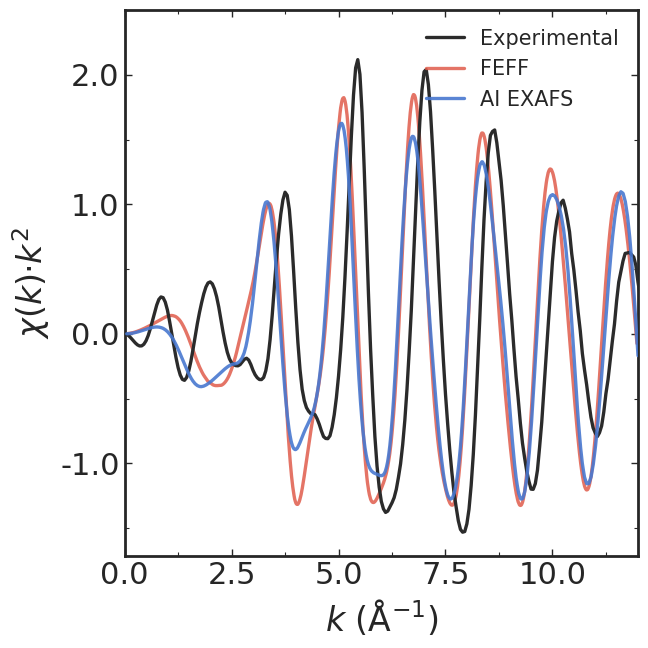

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# --- Style foundation ---
sns.set_theme(style="ticks", context="paper", font_scale=2.5)

# Custom palette: keep your semantic colors but polish them
colors = {
    "Experimental": "#2b2b2b",   # near-black
    "FEFF":         "#e05c4b",   # muted red
    "AI EXAFS":     "#4878d0",   # cleaner blue
}

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(exp_krange,  exp_kchi,  color=colors["Experimental"],
        lw=2.4, label="Experimental", zorder=3)

ax.plot(feff_krange, feff_kchi, color=colors["FEFF"],
        lw=2.4, label="FEFF", alpha=0.85, zorder=2)
ax.plot(pred_krange, pred_kchi, color=colors["AI EXAFS"],
        lw=2.4, label="AI EXAFS", alpha=0.90, zorder=4)

# --- Axes ---
ax.set_xlim(0, 12.0)
ax.set_ylim(None, 2.5)
ax.set_xlabel(r"$k$ (Å$^{-1}$)", labelpad=6)
ax.set_ylabel(r"$\chi(k)·k^{2}$", labelpad=6)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(2))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(2))
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.1f"))
ax.tick_params(which="both", direction="in", top=True, right=True)

for spine in ax.spines.values():
    spine.set_linewidth(2.0)

# --- Legend ---
leg = ax.legend(
    frameon=False, framealpha=0.9, edgecolor="0.8",
    loc="upper right", fontsize=15,
    handlelength=1.8, handletextpad=0.8,
)

# --- Spines ---
sns.despine(ax=ax, top=False, right=False)  # keep all four — looks cleaner for EXAFS

fig.tight_layout()
plt.savefig("./showcase_ptcl6_kspace.svg")

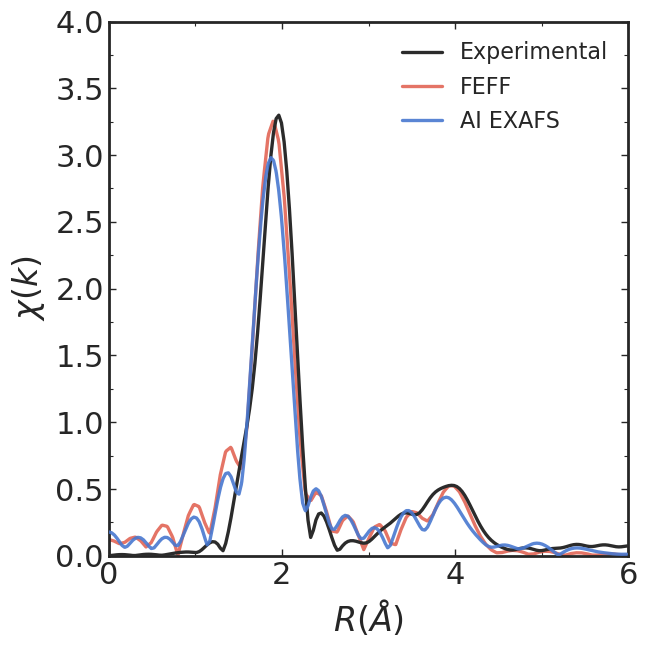

In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# --- Style foundation ---
sns.set_theme(style="ticks", context="paper", font_scale=2.5)

# Custom palette: keep your semantic colors but polish them
colors = {
    "Experimental": "#2b2b2b",   # near-black
    "FEFF":         "#e05c4b",   # muted red
    "AI EXAFS":     "#4878d0",   # cleaner blue
}

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(exp_rrange,  exp_chirmag,  color=colors["Experimental"],
        lw=2.4, label="Experimental", zorder=3)

ax.plot(feff_rrange, feff_chirmag, color=colors["FEFF"],
        lw=2.4, label="FEFF", alpha=0.85, zorder=2)
ax.plot(pred_rrange, pred_chirmag, color=colors["AI EXAFS"],
        lw=2.4, label="AI EXAFS", alpha=0.90, zorder=4)

# --- Axes ---
ax.set_xlim(0, 6.0)
ax.set_ylim(0, 4.0)
ax.set_xlabel(r"$R (\AA)$", labelpad=6)
ax.set_ylabel(r"$\chi(k)$", labelpad=6)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(2))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(2))
ax.tick_params(which="both", direction="in", top=True, right=True)

for spine in ax.spines.values():
    spine.set_linewidth(2.0)

# --- Legend ---
leg = ax.legend(
    frameon=False, framealpha=0.9, edgecolor="0.8",
    loc="upper right", fontsize=16,
    handlelength=1.8, handletextpad=0.8,
)

# --- Spines ---
sns.despine(ax=ax, top=False, right=False)  # keep all four — looks cleaner for EXAFS

fig.tight_layout()
plt.savefig("./showcase_ptcl6_rspace.svg")

### 2) Pt-SAC Impregnation

In [10]:
# Loading experimental EXAFS for SAC PtCl5 Impregnation
exp_sac_kspace = np.loadtxt("./outputs/ptcl5_sac/exp_sac_kspace.csv", delimiter=",", skiprows=1)
exp_sac_krange = exp_sac_kspace[:, 0]
exp_sac_kchi = exp_sac_kspace[:, 1]

exp_sac_rspace = np.loadtxt("./outputs/ptcl5_sac/exp_sac_rspace.csv", delimiter=",", skiprows=1)
exp_sac_rrange = exp_sac_rspace[:, 0]
exp_sac_chirmag = exp_sac_rspace[:, 1]

In [11]:
# Loading FEFF EXAFS for SAC PtCl5 Impregnation
feff_sac_kspace = np.loadtxt("./outputs/ptcl5_sac/feff_sac_kspace.csv", delimiter=",", skiprows=1)
feff_sac_krange = feff_sac_kspace[:, 0]
feff_sac_kchi = feff_sac_kspace[:, 1]

feff_sac_rspace = np.loadtxt("./outputs/ptcl5_sac/feff_sac_rspace.csv", delimiter=",", skiprows=1)
feff_sac_rrange = feff_sac_rspace[:, 0]
feff_sac_chirmag = feff_sac_rspace[:, 1]

In [12]:
# Load AI EXAFS for SAC PtCl5
ai_sac_kspace = np.loadtxt("./outputs/ptcl5_sac/ai_sac_kspace.csv", delimiter=",", skiprows=1)
ai_sac_krange = ai_sac_kspace[:, 0]
ai_sac_kchi = ai_sac_kspace[:, 1]

ai_sac_rspace = np.loadtxt("./outputs/ptcl5_sac/ai_sac_rspace.csv", delimiter=",", skiprows=1)
ai_sac_rrange = ai_sac_rspace[:, 0]
ai_sac_chirmag = ai_sac_rspace[:, 1]

In [13]:
# Getting Arrays for all three spectra (K-space)
exp_arr_k = get_array(exp_sac_krange, exp_sac_kchi, target_dim=800)
feff_arr_k = get_array(feff_sac_krange, feff_sac_kchi, target_dim=800)
ai_arr_k = get_array(ai_sac_krange, ai_sac_kchi, target_dim=800)

# Slice K-space between 3.0 - 12.0
exp_arr_k_sl = slice_array(exp_arr_k, xlim=[3.0, 12], target_dim=800)
feff_arr_k_sl = slice_array(feff_arr_k, xlim=[3.0, 12], target_dim=800)
ai_arr_k_sl = slice_array(ai_arr_k, xlim=[3.0, 12], target_dim=800)

# FEFF vs AI R-factor (K-space)
feff_ai_loss = r_factor(feff_arr_k_sl[:, 1], ai_arr_k_sl[:, 1])
print(f"[K-space] R-Factor FEFF vs AI: {feff_ai_loss:.5f}")

# Getting Arrays for all three spectra (R-space)
exp_arr_r = get_array(exp_sac_rrange, exp_sac_chirmag, target_dim=800)
feff_arr_r = get_array(feff_sac_rrange, feff_sac_chirmag, target_dim=800)
ai_arr_r = get_array(ai_sac_rrange, ai_sac_chirmag, target_dim=800)

# Slice R-space between 0.5 - 6.0
exp_arr_r_sl = slice_array(exp_arr_r, xlim=[0.5, 6], target_dim=800)
ai_arr_r_sl = slice_array(ai_arr_r, xlim=[0.5, 6], target_dim=800)
feff_arr_r_sl = slice_array(feff_arr_r, xlim=[0.5, 6], target_dim=800)

# FEFF vs AI R-factor (R-space)
feff_ai_loss_r = r_factor(feff_arr_r_sl[:, 1], ai_arr_r_sl[:, 1])
print(f"[R-space] R-Factor FEFF vs AI: {feff_ai_loss_r:.5f}")

[K-space] R-Factor FEFF vs AI: 0.03611
[R-space] R-Factor FEFF vs AI: 0.02644


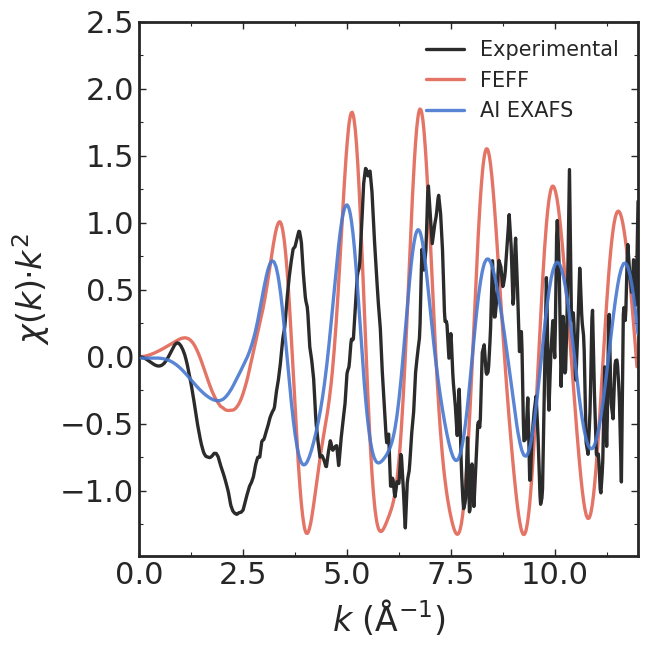

In [14]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# --- Style foundation ---
sns.set_theme(style="ticks", context="paper", font_scale=2.5)

# Custom palette: keep your semantic colors but polish them
colors = {
    "Experimental": "#2b2b2b",   # near-black
    "FEFF":         "#e05c4b",   # muted red
    "AI EXAFS":     "#4878d0",   # cleaner blue
}

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(exp_sac_krange,  exp_sac_kchi,  color=colors["Experimental"],
        lw=2.4, label="Experimental", zorder=3)

ax.plot(feff_krange, feff_kchi, color=colors["FEFF"],
        lw=2.4, label="FEFF", alpha=0.85, zorder=2)
ax.plot(ai_sac_krange, ai_sac_kchi, color=colors["AI EXAFS"],
        lw=2.4, label="AI EXAFS", alpha=0.90, zorder=4)

# --- Axes ---
ax.set_xlim(0, 12.0)
ax.set_ylim(None, 2.5)
ax.set_xlabel(r"$k$ (Å$^{-1}$)", labelpad=6)
ax.set_ylabel(r"$\chi(k)·k^{2}$", labelpad=6)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(2))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(2))
ax.tick_params(which="both", direction="in", top=True, right=True)


for spine in ax.spines.values():
    spine.set_linewidth(2.0)

# --- Legend ---
leg = ax.legend(
    frameon=False, framealpha=0.9, edgecolor="0.8",
    loc="upper right", fontsize=15,
    handlelength=1.8, handletextpad=0.8,
)

# --- Spines ---
sns.despine(ax=ax, top=False, right=False)  # keep all four — looks cleaner for EXAFS

fig.tight_layout()
plt.savefig("./showcase_SAC_kspace.svg")

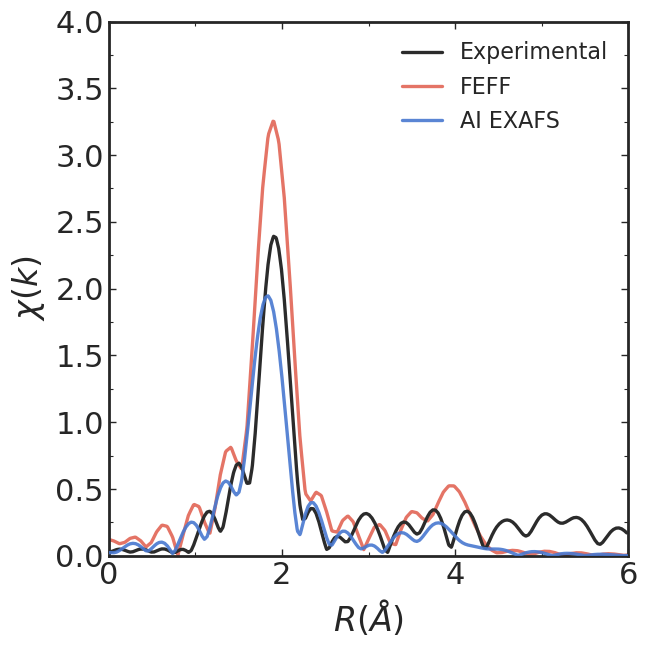

In [15]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# --- Style foundation ---
sns.set_theme(style="ticks", context="paper", font_scale=2.5)

# Custom palette: keep your semantic colors but polish them
colors = {
    "Experimental": "#2b2b2b",   # near-black
    "FEFF":         "#e05c4b",   # muted red
    "AI EXAFS":     "#4878d0",   # cleaner blue
}

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(exp_sac_rrange,  exp_sac_chirmag,  color=colors["Experimental"],
        lw=2.4, label="Experimental", zorder=3)

ax.plot(feff_rrange, feff_chirmag, color=colors["FEFF"],
        lw=2.4, label="FEFF", alpha=0.85, zorder=2)
ax.plot(ai_sac_rrange, ai_sac_chirmag, color=colors["AI EXAFS"],
        lw=2.4, label="AI EXAFS", alpha=0.90, zorder=4)

# --- Axes ---
ax.set_xlim(0, 6.0)
ax.set_ylim(0, 4.0)
ax.set_xlabel(r"$R (\AA)$", labelpad=6)
ax.set_ylabel(r"$\chi(k)$", labelpad=6)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(2))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(2))
ax.tick_params(which="both", direction="in", top=True, right=True)


for spine in ax.spines.values():
    spine.set_linewidth(2.0)

# --- Legend ---
leg = ax.legend(
    frameon=False, framealpha=0.9, edgecolor="0.8",
    loc="upper right", fontsize=16,
    handlelength=1.8, handletextpad=0.8,
)

# --- Spines ---
sns.despine(ax=ax, top=False, right=False)  # keep all four — looks cleaner for EXAFS

fig.tight_layout()
plt.savefig("./showcase_SAC_rspace.svg")